# [빅데이터 분석 과제3] 특성 공학(Feature Engineering) 파이프라인 구현 및 성능 비교 실험
**데이터셋:** Titanic - Machine Learning from Disaster (Kaggle) / **과제:** 생존 여부 예측 (이진 분류)

**실험 설계 요약**
- `train.csv`(891행)만 사용 → **80% 학습 / 20% 홀드아웃**(stratify, seed=42)으로 분할. test.csv는 정답(Survived)이 없어 평가에 쓸 수 없음.
- 모든 전처리(결측치 대체·인코딩·스케일링·변수 선택)는 `Pipeline` + `ColumnTransformer` 안에서 **학습 fold로만 fit** → 데이터 누수(leakage) 방지
- 모든 비교 실험은 학습 80%에서 **5-fold × 2회 반복 Stratified CV(총 10회)** 의 평균±표준편차로 비교하고, 홀드아웃 20%는 최종 확인용으로만 사용
- 모델: Logistic Regression / Random Forest / XGBoost / LightGBM

## 0. 환경 설정

In [1]:
import warnings, os, json, time
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import font_manager
from joblib import Parallel, delayed

import sklearn, xgboost, lightgbm
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, MinMaxScaler, RobustScaler
from sklearn.feature_selection import SelectFromModel, SelectKBest, f_classif, RFE
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, classification_report)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

SEED = 42
N_JOBS = -1
os.makedirs('figures', exist_ok=True); os.makedirs('results', exist_ok=True)

sns.set_theme(style='whitegrid')
try:
    import koreanize_matplotlib          # pip install koreanize-matplotlib (한글 폰트)
except ImportError:
    avail = {f.name for f in font_manager.fontManager.ttflist}
    for fam in ['NanumGothic', 'Malgun Gothic', 'AppleGothic', 'Noto Sans CJK KR', 'Noto Sans CJK JP']:
        if fam in avail:
            plt.rcParams['font.family'] = fam; break
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 100

def savefig(name):
    plt.tight_layout()
    plt.savefig(f'figures/{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

print('sklearn', sklearn.__version__, '| xgboost', xgboost.__version__, '| lightgbm', lightgbm.__version__)

sklearn 1.6.1 | xgboost 3.4.1 | lightgbm 4.6.0


## STEP 01. 데이터 준비

In [2]:
DATA_PATH = next(p for p in ['train.csv', 'data/train.csv', '/content/train.csv', '/kaggle/input/titanic/train.csv'] if os.path.exists(p))
df = pd.read_csv(DATA_PATH)
print('데이터 shape:', df.shape)
print('타겟 변수: Survived (0=사망, 1=생존)')
df.head()

데이터 shape: (891, 12)
타겟 변수: Survived (0=사망, 1=생존)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
desc = {
 'PassengerId': ('승객 고유 번호 (식별자, 모델에서 제외)', '식별자'),
 'Survived':    ('생존 여부 (0=사망, 1=생존)  ← 타겟', '범주(이진)'),
 'Pclass':      ('객실 등급 (1=1등석, 2=2등석, 3=3등석)', '범주(순서형)'),
 'Name':        ('승객 이름 (호칭 Title 추출에 사용)', '텍스트'),
 'Sex':         ('성별 (male/female)', '범주(명목형)'),
 'Age':         ('나이', '수치(연속형)'),
 'SibSp':       ('동승한 형제/자매/배우자 수', '수치(이산형)'),
 'Parch':       ('동승한 부모/자녀 수', '수치(이산형)'),
 'Ticket':      ('티켓 번호', '텍스트'),
 'Fare':        ('운임 요금', '수치(연속형)'),
 'Cabin':       ('객실 번호 (결측 매우 많음)', '텍스트'),
 'Embarked':    ('탑승 항구 (C=Cherbourg, Q=Queenstown, S=Southampton)', '범주(명목형)'),
}
col_table = pd.DataFrame({'컬럼': df.columns,
                          '설명': [desc[c][0] for c in df.columns],
                          '유형': [desc[c][1] for c in df.columns],
                          'dtype': [str(t) for t in df.dtypes],
                          '결측 수': df.isna().sum().values,
                          '고유값 수': df.nunique().values})
col_table.to_csv('results/column_description.csv', index=False, encoding='utf-8-sig')
col_table

,컬럼,설명,유형,dtype,결측 수,고유값 수
0,PassengerId,"승객 고유 번호 (식별자, 모델에서 제외)",식별자,int64,0,891
1,Survived,"생존 여부 (0=사망, 1=생존) ← 타겟",범주(이진),int64,0,2
2,Pclass,"객실 등급 (1=1등석, 2=2등석, 3=3등석)",범주(순서형),int64,0,3
3,Name,승객 이름 (호칭 Title 추출에 사용),텍스트,object,0,891
4,Sex,성별 (male/female),범주(명목형),object,0,2
5,Age,나이,수치(연속형),float64,177,88
6,SibSp,동승한 형제/자매/배우자 수,수치(이산형),int64,0,7
7,Parch,동승한 부모/자녀 수,수치(이산형),int64,0,7
8,Ticket,티켓 번호,텍스트,object,0,681
9,Fare,운임 요금,수치(연속형),float64,0,248


## STEP 02. 탐색적 데이터 분석 (EDA)

,결측 수,결측 비율(%)
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


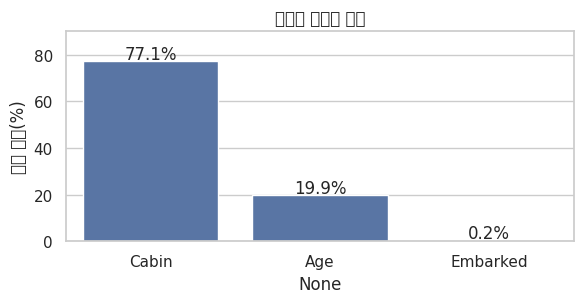

In [4]:
# 1) 결측치 비율
miss = pd.DataFrame({'결측 수': df.isna().sum(), '결측 비율(%)': (df.isna().mean()*100).round(2)})
miss = miss[miss['결측 수'] > 0].sort_values('결측 비율(%)', ascending=False)
miss.to_csv('results/missing.csv', encoding='utf-8-sig')
display(miss)
plt.figure(figsize=(6, 3.2))
ax = sns.barplot(x=miss.index, y=miss['결측 비율(%)'], color='#4C72B0')
for i, v in enumerate(miss['결측 비율(%)']): ax.text(i, v + 1, f'{v:.1f}%', ha='center')
plt.ylabel('결측 비율(%)'); plt.title('컬럼별 결측치 비율'); plt.ylim(0, 90)
savefig('eda_missing')

,변수,하한,상한,이상치 수,비율(%),최댓값
0,Age,-6.69,64.81,11,1.5,80.0000
1,Fare,-26.72,65.63,116,13.0,512.3292
2,SibSp,-1.50,2.50,46,5.2,8.0000
3,Parch,0.00,0.00,213,23.9,6.0000


Fare == 0 인 승객 수: 15


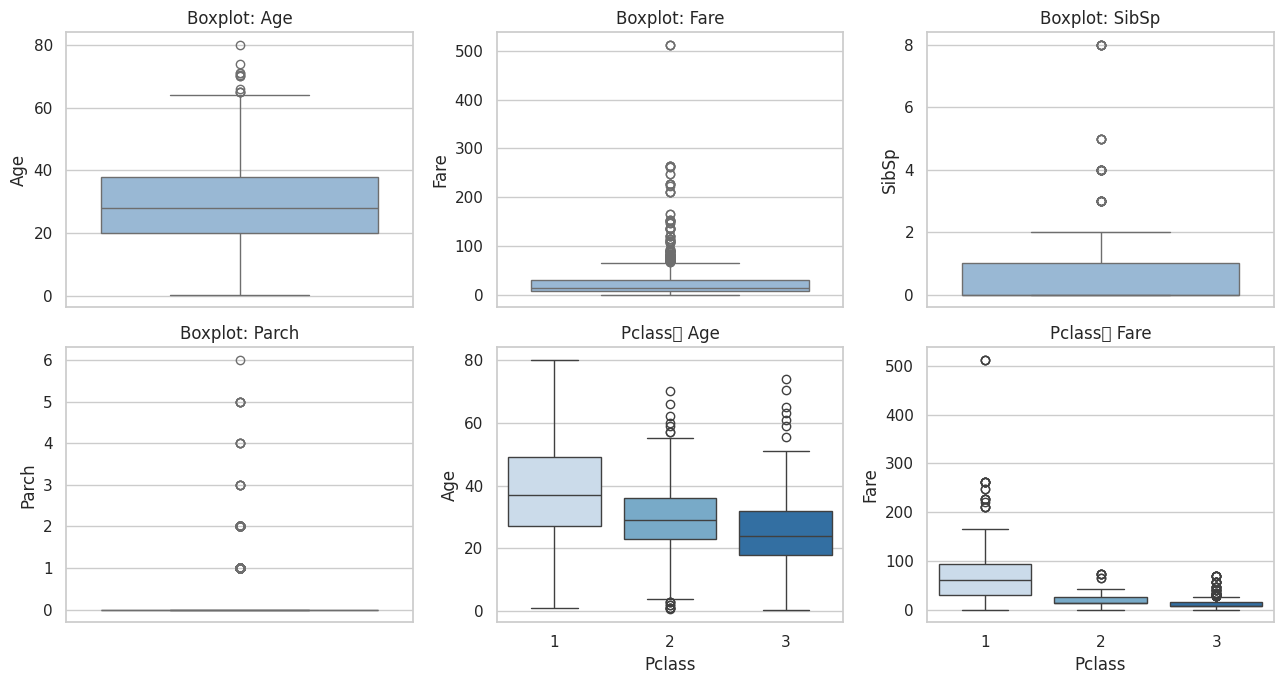

In [5]:
# 2) 이상치 탐색 (IQR 기준: Q1-1.5*IQR 미만 또는 Q3+1.5*IQR 초과)
rows = []
for c in ['Age', 'Fare', 'SibSp', 'Parch']:
    s = df[c].dropna(); q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    n = int(((s < lo) | (s > hi)).sum())
    rows.append({'변수': c, '하한': round(lo, 2), '상한': round(hi, 2), '이상치 수': n, '비율(%)': round(n/len(s)*100, 1), '최댓값': s.max()})
outlier = pd.DataFrame(rows); outlier.to_csv('results/outliers.csv', index=False, encoding='utf-8-sig')
display(outlier)
print('Fare == 0 인 승객 수:', int((df.Fare == 0).sum()))

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, c in zip(axes.ravel()[:4], ['Age', 'Fare', 'SibSp', 'Parch']):
    sns.boxplot(y=df[c], ax=ax, color='#8FB8DE'); ax.set_title(f'Boxplot: {c}')
sns.boxplot(data=df, x='Pclass', y='Age', ax=axes[1, 1], palette='Blues'); axes[1, 1].set_title('Pclass별 Age')
sns.boxplot(data=df, x='Pclass', y='Fare', ax=axes[1, 2], palette='Blues'); axes[1, 2].set_title('Pclass별 Fare')
savefig('eda_boxplot')

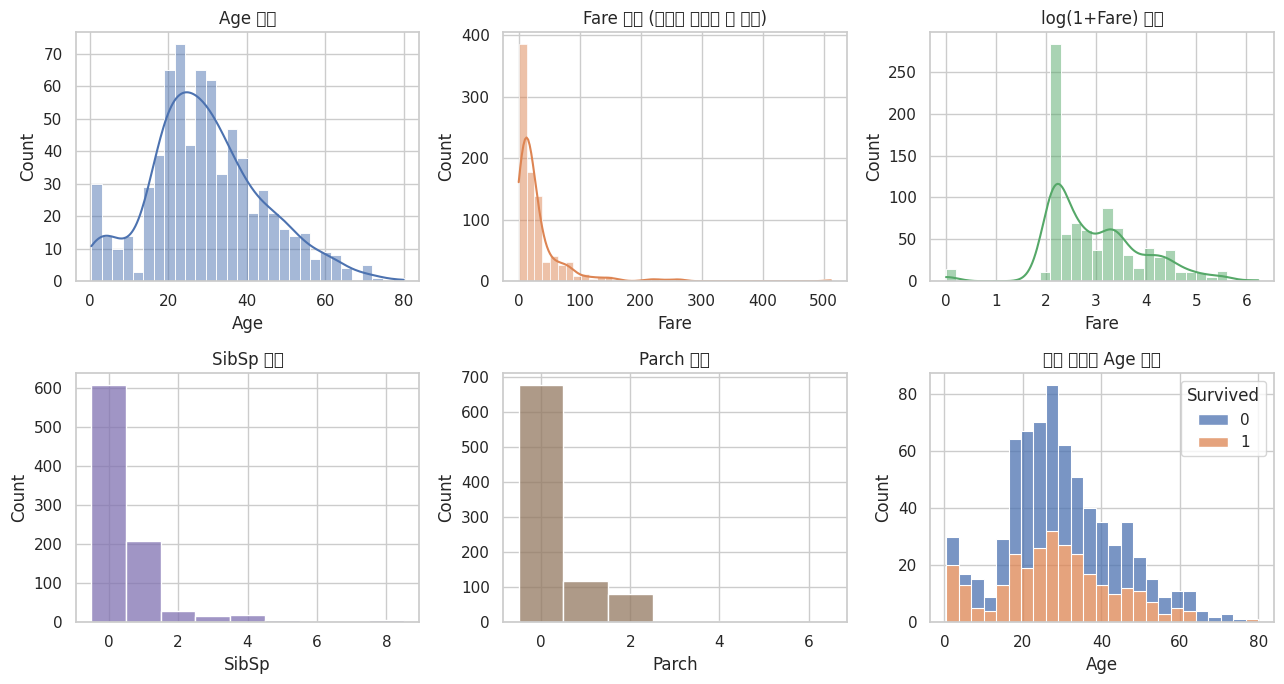

왜도(skewness): {'Age': 0.39, 'Fare': 4.79, 'SibSp': 3.7, 'Parch': 2.75}


In [6]:
# 3) 변수 분포 시각화 (Histogram)
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
sns.histplot(df['Age'].dropna(), bins=30, kde=True, ax=axes[0, 0], color='#4C72B0'); axes[0, 0].set_title('Age 분포')
sns.histplot(df['Fare'], bins=40, kde=True, ax=axes[0, 1], color='#DD8452'); axes[0, 1].set_title('Fare 분포 (오른쪽 꼬리가 긴 분포)')
sns.histplot(np.log1p(df['Fare']), bins=30, kde=True, ax=axes[0, 2], color='#55A868'); axes[0, 2].set_title('log(1+Fare) 분포')
sns.histplot(df['SibSp'], discrete=True, ax=axes[1, 0], color='#8172B2'); axes[1, 0].set_title('SibSp 분포')
sns.histplot(df['Parch'], discrete=True, ax=axes[1, 1], color='#937860'); axes[1, 1].set_title('Parch 분포')
sns.histplot(data=df.dropna(subset=['Age']), x='Age', hue='Survived', bins=25, multiple='stack', ax=axes[1, 2]); axes[1, 2].set_title('생존 여부별 Age 분포')
savefig('eda_hist')
print('왜도(skewness):', df[['Age', 'Fare', 'SibSp', 'Parch']].skew().round(2).to_dict())

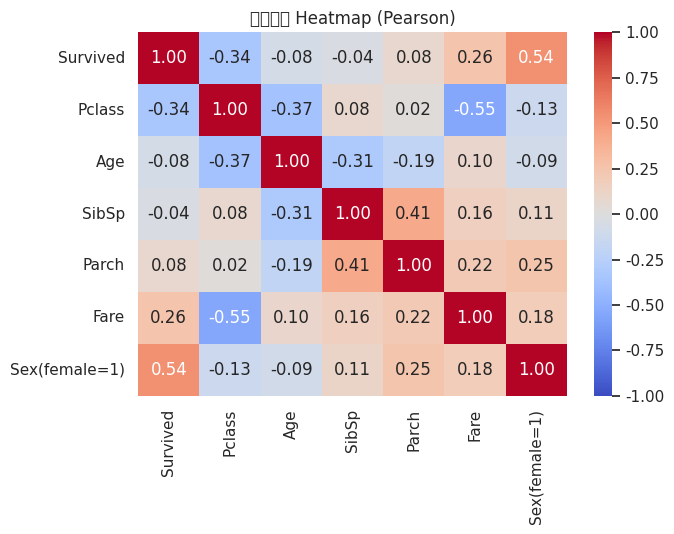

Sex(female=1)    0.543
Pclass          -0.338
Fare             0.257
Parch            0.082
Age             -0.077
SibSp           -0.035
Name: Survived, dtype: float64


In [7]:
# 4) 상관관계 분석 (Heatmap)
num_df = df[['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']].copy()
num_df['Sex(female=1)'] = (df['Sex'] == 'female').astype(int)
corr = num_df.corr()
corr.round(3).to_csv('results/correlation.csv', encoding='utf-8-sig')
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('상관관계 Heatmap (Pearson)')
savefig('eda_heatmap')
print(corr['Survived'].drop('Survived').sort_values(key=abs, ascending=False).round(3))

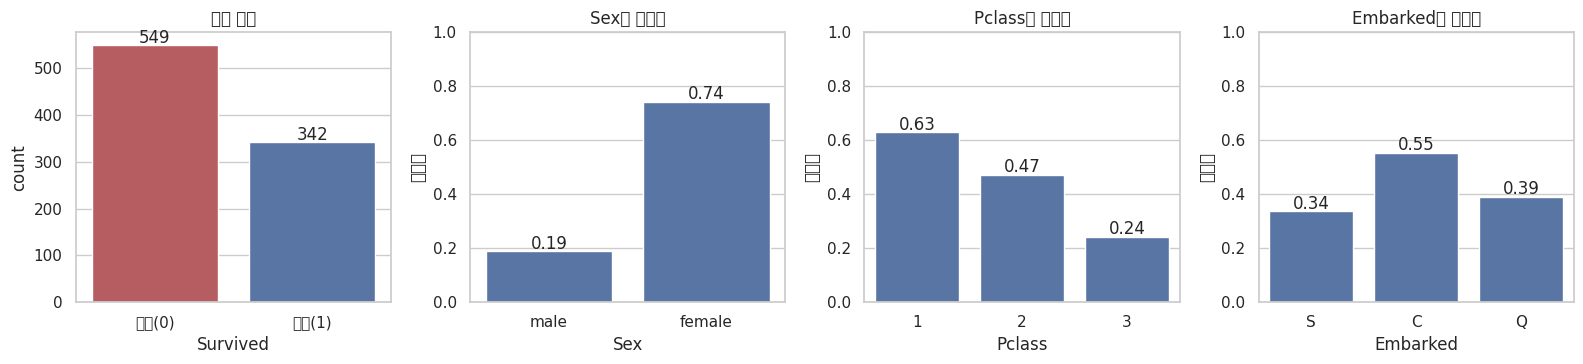

{'n_rows': 891,
 'n_cols': 12,
 'survival_rate': 0.3838,
 'death_rate': 0.6162,
 'surv_by_sex': {'female': 0.742, 'male': 0.189},
 'surv_by_pclass': {1: 0.63, 2: 0.473, 3: 0.242},
 'surv_by_embarked': {'C': 0.554, 'Q': 0.39, 'S': 0.337},
 'age_median': 28.0,
 'age_mean': 29.7,
 'fare_median': 14.4542,
 'fare_mean': 32.2}

In [8]:
# 5) 타겟 변수 분포 + 주요 범주형 변수별 생존율 (Countplot / Barplot)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
sns.countplot(data=df, x='Survived', ax=axes[0], palette=['#C44E52', '#4C72B0'])
for p in axes[0].patches: axes[0].annotate(f'{int(p.get_height())}', (p.get_x()+p.get_width()/2, p.get_height()+5), ha='center')
axes[0].set_xticklabels(['사망(0)', '생존(1)']); axes[0].set_title('타겟 분포')
for ax, c in zip(axes[1:], ['Sex', 'Pclass', 'Embarked']):
    sns.barplot(data=df, x=c, y='Survived', ax=ax, color='#4C72B0', errorbar=None)
    for p in ax.patches: ax.annotate(f'{p.get_height():.2f}', (p.get_x()+p.get_width()/2, p.get_height()+0.01), ha='center')
    ax.set_ylim(0, 1); ax.set_ylabel('생존율'); ax.set_title(f'{c}별 생존율')
savefig('eda_target')

vc = df['Survived'].value_counts(normalize=True)
eda_summary = {
  'n_rows': int(len(df)), 'n_cols': int(df.shape[1]),
  'survival_rate': round(float(vc[1]), 4), 'death_rate': round(float(vc[0]), 4),
  'surv_by_sex': df.groupby('Sex')['Survived'].mean().round(3).to_dict(),
  'surv_by_pclass': df.groupby('Pclass')['Survived'].mean().round(3).to_dict(),
  'surv_by_embarked': df.groupby('Embarked')['Survived'].mean().round(3).to_dict(),
  'age_median': float(df['Age'].median()), 'age_mean': round(float(df['Age'].mean()), 2),
  'fare_median': float(df['Fare'].median()), 'fare_mean': round(float(df['Fare'].mean()), 2),
}
json.dump(eda_summary, open('results/eda_summary.json', 'w'), ensure_ascii=False, indent=1)
eda_summary

### EDA 요약 (데이터 품질 / 불균형 / 주요 변수 특징)
위 결과를 바탕으로 한 해석은 보고서(PDF)와 노트북 마지막 '최종 결론'에 정리했다.

## STEP 03. 특성 공학 파이프라인 구현
### 3-0. 파생 변수 생성 (행 단위 규칙 변환이라 학습/검증 데이터 간 누수 없음)
| 파생 변수 | 생성 방법 | 의도 |
|---|---|---|
| `Title` | 이름에서 호칭 추출 → Mr/Mrs/Miss/Master/Rare | 성별+나이+사회적 지위를 함께 반영 |
| `FamilySize` | SibSp + Parch + 1 | 가족 규모 |
| `IsAlone` | FamilySize == 1 | 혼자 탑승 여부 |
| `FarePerPerson` | Fare / FamilySize | 1인당 운임 (Fare는 가족 단위로 청구되는 경우가 있음) |
| `HasCabin` | Cabin 값 존재 여부 | 결측이 77%인 Cabin을 정보량 있는 이진 변수로 변환 |
| `AgeGroup` | Child(<12) / Teen(<18) / YoungAdult(<35) / Adult(<60) / Senior / Unknown | 나이 구간화 + 결측을 별도 범주로 |

In [9]:
def add_features(d):
    d = d.copy()
    title = d['Name'].str.extract(r',\s*([^\.]+)\.', expand=False).str.strip()
    title_map = {'Mr': 'Mr', 'Mrs': 'Mrs', 'Mme': 'Mrs', 'Miss': 'Miss', 'Ms': 'Miss', 'Mlle': 'Miss', 'Master': 'Master'}
    d['Title'] = title.map(title_map).fillna('Rare')
    d['FamilySize'] = d['SibSp'] + d['Parch'] + 1
    d['IsAlone'] = (d['FamilySize'] == 1).astype(int)
    d['FarePerPerson'] = d['Fare'] / d['FamilySize']
    d['HasCabin'] = d['Cabin'].notna().astype(int)
    ag = pd.cut(d['Age'], bins=[0, 12, 18, 35, 60, 120], right=False,
                labels=['Child', 'Teen', 'YoungAdult', 'Adult', 'Senior']).astype(object)
    d['AgeGroup'] = ag.where(d['Age'].notna(), 'Unknown')
    return d

full = add_features(df)
print('원본 컬럼 수:', df.shape[1], '→ 파생 변수 추가 후:', full.shape[1])
full[['Name', 'Title', 'SibSp', 'Parch', 'FamilySize', 'IsAlone', 'Fare', 'FarePerPerson', 'Cabin', 'HasCabin', 'Age', 'AgeGroup']].head(8)

원본 컬럼 수: 12 → 파생 변수 추가 후: 18


,Name,Title,SibSp,Parch,FamilySize,IsAlone,Fare,FarePerPerson,Cabin,HasCabin,Age,AgeGroup
0,"Braund, Mr. Owen Harris",Mr,1,0,2,0,7.2500,3.62500,NaN,0,22.0,YoungAdult
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,1,0,2,0,71.2833,35.64165,C85,1,38.0,Adult
2,"Heikkinen, Miss. Laina",Miss,0,0,1,1,7.9250,7.92500,NaN,0,26.0,YoungAdult
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,1,0,2,0,53.1000,26.55000,C123,1,35.0,Adult
4,"Allen, Mr. William Henry",Mr,0,0,1,1,8.0500,8.05000,NaN,0,35.0,Adult
5,"Moran, Mr. James",Mr,0,0,1,1,8.4583,8.45830,NaN,0,NaN,Unknown
6,"McCarthy, Mr. Timothy J",Mr,0,0,1,1,51.8625,51.86250,E46,1,54.0,Adult
7,"Palsson, Master. Gosta Leonard",Master,3,1,5,0,21.0750,4.21500,NaN,0,2.0,Child


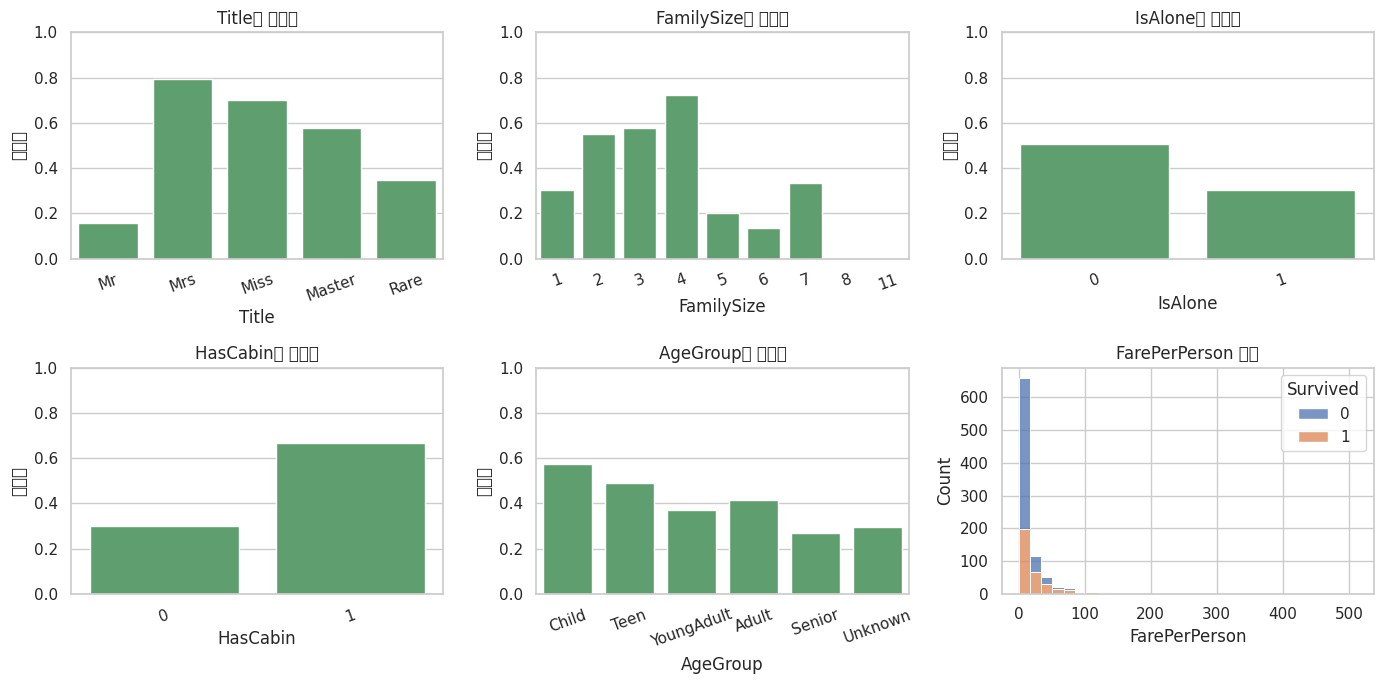

,count,mean
Title,,
Master,40,0.575
Miss,185,0.703
Mr,517,0.157
Mrs,126,0.794
Rare,23,0.348


In [10]:
# 파생 변수와 생존율의 관계
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.ravel(), ['Title', 'FamilySize', 'IsAlone', 'HasCabin', 'AgeGroup']):
    order = ['Child', 'Teen', 'YoungAdult', 'Adult', 'Senior', 'Unknown'] if c == 'AgeGroup' else None
    sns.barplot(data=full, x=c, y='Survived', ax=ax, color='#55A868', errorbar=None, order=order)
    ax.set_ylim(0, 1); ax.set_ylabel('생존율'); ax.set_title(f'{c}별 생존율')
    ax.tick_params(axis='x', rotation=20)
sns.histplot(data=full, x='FarePerPerson', hue='Survived', bins=30, multiple='stack', ax=axes[1, 2]); axes[1, 2].set_title('FarePerPerson 분포')
savefig('fe_survival')
full.groupby('Title')['Survived'].agg(['count', 'mean']).round(3)

### 3-1. 파이프라인 구성요소 정의
- **결측치 처리:** `mean` / `median` / `most_frequent` (Age에 적용, 범주형 Embarked는 항상 최빈값) / `dropna`(학습 fold에서 결측 행 삭제) / `none`(대체 없이 상수 -1 → Base 전용)
  - `dropna`는 *학습 fold의 결측 행만 삭제*하고, **검증 fold는 동일하게 평가**(비교 가능하도록 검증 데이터는 학습셋 중앙값으로 채움)
- **인코딩:** `onehot`(OneHotEncoder) / `label`(OrdinalEncoder; 범주형 문자열 → 정수 코드)
- **스케일링:** `none` / `standard` / `minmax` / `robust` — **연속형·이산형 수치 변수에만 적용**(이진 변수·인코딩된 범주형은 제외)
- **변수 선택:** RF 중요도 상위 N개(`SelectFromModel`), `SelectKBest(f_classif)`, `RFE(LogisticRegression)` — 모두 파이프라인 내부에서 학습 fold로만 fit

In [11]:
# ---------- 변수 그룹 ----------
GROUPS = {
 'base':   dict(num=['Pclass', 'Age', 'SibSp', 'Parch', 'Fare'], bin=[], cat=[]),          # Base: 원본 수치형만
 'orig':   dict(num=['Pclass', 'Age', 'SibSp', 'Parch', 'Fare'], bin=[], cat=['Sex', 'Embarked']),
 'family': dict(num=['FamilySize'], bin=['IsAlone'], cat=[]),
 'title':  dict(num=[], bin=[], cat=['Title']),
 'cabin':  dict(num=[], bin=['HasCabin'], cat=[]),
 'farepp': dict(num=['FarePerPerson'], bin=[], cat=[]),
 'agegrp': dict(num=[], bin=[], cat=['AgeGroup']),
}
ALL_FE = ['orig', 'family', 'title', 'cabin', 'farepp', 'agegrp']

def cols_of(groups):
    out = {'num': [], 'bin': [], 'cat': []}
    for g in groups:
        for k in out: out[k] += GROUPS[g][k]
    return out['num'], out['bin'], out['cat']

# ---------- 전처리 구성요소 ----------
def num_imputer(kind):
    return {'mean': SimpleImputer(strategy='mean'),
            'median': SimpleImputer(strategy='median'),
            'most_frequent': SimpleImputer(strategy='most_frequent'),
            'dropna': SimpleImputer(strategy='median'),                       # 검증 fold 예측용 (학습 행은 별도로 삭제)
            'none': SimpleImputer(strategy='constant', fill_value=-1)}[kind]  # Base: 모델이 돌아가기 위한 최소 처리(sentinel)

def make_scaler(kind):
    return {'none': 'passthrough', 'standard': StandardScaler(), 'minmax': MinMaxScaler(), 'robust': RobustScaler()}[kind]

def make_selector(fs):
    if fs is None: return 'passthrough'
    kind, k = fs
    if kind == 'rf':    return SelectFromModel(RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1), threshold=-np.inf, max_features=k)
    if kind == 'kbest': return SelectKBest(f_classif, k=k)
    if kind == 'rfe':   return RFE(LogisticRegression(max_iter=2000), n_features_to_select=k)
    raise ValueError(kind)

def build_pipeline(model, groups, imputer='median', encoder='onehot', scaler='standard', fs=None, **_):
    num, bin_, cat = cols_of(groups)
    tfs = []
    if num:
        tfs.append(('num', Pipeline([('imp', num_imputer(imputer)), ('scale', make_scaler(scaler))]), num))
    if bin_:
        tfs.append(('bin', 'passthrough', bin_))
    if cat:
        enc = (OneHotEncoder(handle_unknown='ignore', sparse_output=False) if encoder == 'onehot'
               else OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
        cat_imp = SimpleImputer(strategy='constant', fill_value='Missing') if imputer == 'none' else SimpleImputer(strategy='most_frequent')
        tfs.append(('cat', Pipeline([('imp', cat_imp), ('enc', enc)]), cat))
    prep = ColumnTransformer(tfs, remainder='drop')
    return Pipeline([('prep', prep), ('fs', make_selector(fs)), ('model', model)])

def get_model(name):
    return {
     'LR':   LogisticRegression(max_iter=2000, random_state=SEED),
     'RF':   RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1),
     'XGB':  XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
                           eval_metric='logloss', random_state=SEED, n_jobs=1, verbosity=0),
     'LGBM': LGBMClassifier(n_estimators=200, num_leaves=15, learning_rate=0.05, min_child_samples=20, subsample=0.8,
                            subsample_freq=1, colsample_bytree=0.8, random_state=SEED, n_jobs=1, verbose=-1),
    }[name]
MODELS = ['LR', 'RF', 'XGB', 'LGBM']
MODEL_KR = {'LR': 'Logistic Regression', 'RF': 'Random Forest', 'XGB': 'XGBoost', 'LGBM': 'LightGBM'}

# 구성 확인: 원-핫 인코딩 후 총 변수 수
_p = build_pipeline(get_model('LR'), ALL_FE).fit(*[full.drop(columns=['Survived']), full['Survived']])
print('One-Hot 후 변수 수:', len(_p[:-1].get_feature_names_out()))
_p = build_pipeline(get_model('LR'), ALL_FE, encoder='label').fit(*[full.drop(columns=['Survived']), full['Survived']])
print('Label Encoding 후 변수 수:', len(_p[:-1].get_feature_names_out()))

One-Hot 후 변수 수: 25
Label Encoding 후 변수 수: 13


### 3-2. 학습/홀드아웃 분할 및 교차검증 함수

In [12]:
X_all = full.drop(columns=['Survived', 'PassengerId'])
y_all = full['Survived']
X_train, X_hold, y_train, y_hold = train_test_split(X_all, y_all, test_size=0.2, stratify=y_all, random_state=SEED)
print('학습:', X_train.shape, ' 홀드아웃:', X_hold.shape, '| 학습 생존율 %.3f / 홀드아웃 생존율 %.3f' % (y_train.mean(), y_hold.mean()))

CV_SPLITS = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED).split(X_train, y_train))
METRICS = ['acc', 'prec', 'rec', 'f1', 'auc']

def fit_eval(pipe, Xtr, ytr, Xva, yva, drop_na=False):
    p = clone(pipe)
    if drop_na:   # 학습 데이터에서 Age/Embarked 결측 행 삭제 (검증 데이터는 그대로)
        keep = Xtr[['Age', 'Embarked']].notna().all(axis=1).values
        Xtr, ytr = Xtr[keep], ytr[keep]
    p.fit(Xtr, ytr)
    pv = p.predict_proba(Xva)[:, 1]; pr = (pv >= 0.5).astype(int)
    ptr = p.predict_proba(Xtr)[:, 1]
    return dict(acc=accuracy_score(yva, pr), prec=precision_score(yva, pr, zero_division=0),
                rec=recall_score(yva, pr), f1=f1_score(yva, pr), auc=roc_auc_score(yva, pv),
                train_acc=accuracy_score(ytr, (ptr >= 0.5).astype(int)), n_train=len(ytr))

_cache = {}
def run_cv(model_name, cfg):
    key = (model_name, json.dumps(cfg, sort_keys=True, default=str))
    if key in _cache: return _cache[key]
    pipe = build_pipeline(get_model(model_name), **cfg)
    rows = Parallel(n_jobs=N_JOBS)(delayed(fit_eval)(pipe, X_train.iloc[tr], y_train.iloc[tr].values,
                                                    X_train.iloc[va], y_train.iloc[va].values, cfg.get('drop_na', False))
                                  for tr, va in CV_SPLITS)
    r = pd.DataFrame(rows)
    out = {}
    for m in METRICS + ['train_acc']:
        out[m] = r[m].mean(); out[m + '_std'] = r[m].std()
    out['gap'] = out['train_acc'] - out['acc']          # 과적합 지표: 학습 정확도 - 검증 정확도
    _cache[key] = out
    return out

def run_holdout(model_name, cfg):
    pipe = build_pipeline(get_model(model_name), **cfg)
    r = fit_eval(pipe, X_train, y_train.values, X_hold, y_hold.values, cfg.get('drop_na', False))
    return {('hold_' + k): v for k, v in r.items() if k in METRICS}

def fmt(m, s): return f'{m:.3f}±{s:.3f}'
t0 = time.time()

학습: (712, 16)  홀드아웃: (179, 16) | 학습 생존율 0.383 / 홀드아웃 생존율 0.385


## STEP 05(선행). 실험 비교표 — Base / Exp-1 / Exp-2 / Exp-3
과제에서 요구한 4가지 조합을 4개 모델로 평가한다. (Exp-1~3은 파생 변수 포함)

| 실험 | 결측치 처리 | 인코딩 | 스케일링 | Feature Selection |
|---|---|---|---|---|
| Base | 없음(상수 -1) | 없음(수치형만 사용) | 없음 | 없음 |
| Exp-1 | Mean | One-Hot | Standard | X |
| Exp-2 | Median | Label | MinMax | O (RF top-10) |
| Exp-3 | Most Frequent | One-Hot | Robust | O (RF top-10) |

> **Base 정의:** 범주형·텍스트 컬럼은 인코딩 없이 모델에 넣을 수 없으므로 원본 수치형 5개(Pclass, Age, SibSp, Parch, Fare)만 사용한다. Age 결측은 모델이 돌아가도록 -1 상수로만 채웠다(통계적 대체가 아님).

In [13]:
EXPS = {
 'Base':  dict(groups=['base'], imputer='none',          encoder='onehot', scaler='none',     fs=None),
 'Exp-1': dict(groups=ALL_FE,   imputer='mean',          encoder='onehot', scaler='standard', fs=None),
 'Exp-2': dict(groups=ALL_FE,   imputer='median',        encoder='label',  scaler='minmax',   fs=('rf', 10)),
 'Exp-3': dict(groups=ALL_FE,   imputer='most_frequent', encoder='onehot', scaler='robust',   fs=('rf', 10)),
}
rows = []
for en, cfg in EXPS.items():
    for mn in MODELS:
        rows.append({'실험': en, '모델': mn, **run_cv(mn, cfg), **run_holdout(mn, cfg)})
main = pd.DataFrame(rows)
main.to_csv('results/main_table.csv', index=False, encoding='utf-8-sig')

show = main.copy()
for m, nm in [('acc', 'CV Accuracy'), ('auc', 'CV ROC-AUC')]:
    show[nm] = [fmt(a, b) for a, b in zip(main[m], main[m + '_std'])]
print(f'소요시간 {time.time()-t0:.0f}s')
display(show.pivot(index='실험', columns='모델', values='CV Accuracy')[MODELS].loc[list(EXPS)])
display(show.pivot(index='실험', columns='모델', values='CV ROC-AUC')[MODELS].loc[list(EXPS)])
print('--- 홀드아웃(20%) ROC-AUC ---')
display(main.pivot(index='실험', columns='모델', values='hold_auc')[MODELS].loc[list(EXPS)].round(3))

소요시간 83s


모델,LR,RF,XGB,LGBM
실험,,,,
Base,0.712±0.025,0.719±0.029,0.715±0.040,0.730±0.035
Exp-1,0.823±0.028,0.820±0.032,0.829±0.027,0.821±0.032
Exp-2,0.796±0.029,0.817±0.029,0.827±0.028,0.829±0.033
Exp-3,0.811±0.029,0.815±0.025,0.826±0.037,0.824±0.027


모델,LR,RF,XGB,LGBM
실험,,,,
Base,0.725±0.025,0.765±0.025,0.767±0.033,0.767±0.034
Exp-1,0.868±0.026,0.869±0.022,0.883±0.031,0.879±0.035
Exp-2,0.854±0.031,0.872±0.024,0.883±0.033,0.876±0.038
Exp-3,0.867±0.026,0.869±0.028,0.877±0.038,0.874±0.039


--- 홀드아웃(20%) ROC-AUC ---


모델,LR,RF,XGB,LGBM
실험,,,,
Base,0.695,0.677,0.668,0.669
Exp-1,0.873,0.832,0.837,0.838
Exp-2,0.848,0.846,0.829,0.835
Exp-3,0.853,0.840,0.823,0.830


## 단일 요인 비교 실험 (결측치 / 인코딩 / 스케일링)
Exp-1~3은 여러 요인을 동시에 바꾸므로 *어떤 요인이 효과적인지* 알 수 없다. 그래서 **기준 설정(Median · One-Hot · Standard · 파생변수 포함 · 변수 선택 없음)에서 한 번에 한 요인만** 바꿔 비교한다.

In [14]:
BASE_CFG = dict(groups=ALL_FE, imputer='median', encoder='onehot', scaler='standard', fs=None)
SINGLE = {
 '결측치 처리': ('imputer', {'Mean': 'mean', 'Median': 'median', 'Most Frequent': 'most_frequent', 'Drop NA(학습 fold)': 'dropna'}),
 '인코딩':      ('encoder', {'One-Hot': 'onehot', 'Label': 'label'}),
 '스케일링':    ('scaler',  {'None': 'none', 'Standard': 'standard', 'MinMax': 'minmax', 'Robust': 'robust'}),
}
rows = []
for factor, (key, opts) in SINGLE.items():
    for oname, oval in opts.items():
        cfg = {**BASE_CFG, key: oval}
        if key == 'imputer' and oval == 'dropna': cfg['drop_na'] = True
        for mn in MODELS:
            rows.append({'요인': factor, '옵션': oname, '모델': mn, **run_cv(mn, cfg)})
single = pd.DataFrame(rows)
single.to_csv('results/single_factor.csv', index=False, encoding='utf-8-sig')
print(f'소요시간 {time.time()-t0:.0f}s')
for factor in SINGLE:
    s = single[single['요인'] == factor]
    pv = s.pivot(index='옵션', columns='모델', values='auc')[MODELS].loc[list(SINGLE[factor][1])]
    pv['평균'] = pv.mean(axis=1)
    pa = s.pivot(index='옵션', columns='모델', values='acc')[MODELS].loc[list(SINGLE[factor][1])]
    pa['평균'] = pa.mean(axis=1)
    print(f'\n[{factor}] CV ROC-AUC'); display(pv.round(4))
    print(f'[{factor}] CV Accuracy'); display(pa.round(4))

소요시간 136s

[결측치 처리] CV ROC-AUC


모델,LR,RF,XGB,LGBM,평균
옵션,,,,,
Mean,0.8684,0.8688,0.8831,0.8793,0.8749
Median,0.8684,0.8693,0.8810,0.8792,0.8745
Most Frequent,0.8687,0.8663,0.8810,0.8779,0.8735
Drop NA(학습 fold),0.8664,0.8667,0.8743,0.8749,0.8706


[결측치 처리] CV Accuracy


모델,LR,RF,XGB,LGBM,평균
옵션,,,,,
Mean,0.8230,0.8195,0.8286,0.8209,0.8230
Median,0.8230,0.8195,0.8286,0.8244,0.8239
Most Frequent,0.8230,0.8153,0.8258,0.8258,0.8225
Drop NA(학습 fold),0.8223,0.8104,0.8202,0.8146,0.8169



[인코딩] CV ROC-AUC


모델,LR,RF,XGB,LGBM,평균
옵션,,,,,
One-Hot,0.8684,0.8693,0.8810,0.8792,0.8745
Label,0.8538,0.8732,0.8835,0.8795,0.8725


... (2 outputs left out)


[스케일링] CV ROC-AUC


모델,LR,RF,XGB,LGBM,평균
옵션,,,,,
None,0.8678,0.8695,0.8810,0.8796,0.8745
Standard,0.8684,0.8693,0.8810,0.8792,0.8745
MinMax,0.8715,0.8688,0.8810,0.8796,0.8752
Robust,0.8680,0.8694,0.8811,0.8796,0.8745


[스케일링] CV Accuracy


모델,LR,RF,XGB,LGBM,평균
옵션,,,,,
None,0.8244,0.8202,0.8286,0.8258,0.8248
Standard,0.8230,0.8195,0.8286,0.8244,0.8239
MinMax,0.8265,0.8195,0.8286,0.8258,0.8251
Robust,0.8237,0.8195,0.8279,0.8237,0.8237


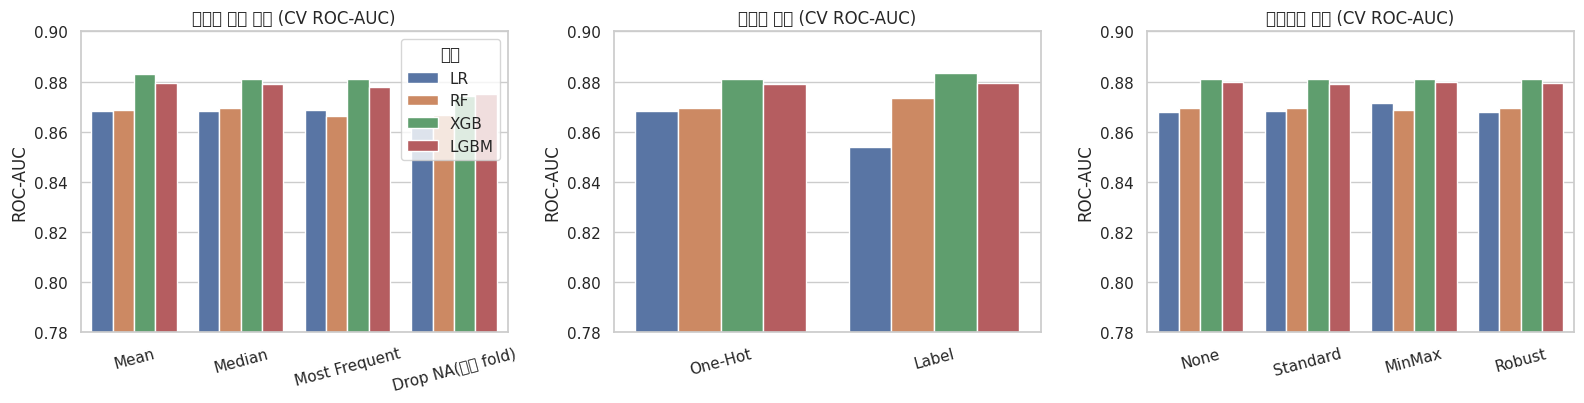

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, factor in zip(axes, SINGLE):
    s = single[single['요인'] == factor]
    sns.barplot(data=s, x='옵션', y='auc', hue='모델', hue_order=MODELS, ax=ax, errorbar=None)
    ax.set_ylim(0.78, 0.90); ax.set_title(f'{factor} 비교 (CV ROC-AUC)'); ax.set_xlabel(''); ax.set_ylabel('ROC-AUC')
    ax.tick_params(axis='x', rotation=15)
    if ax is not axes[0]: ax.get_legend().remove()
savefig('single_factor')

### 파생 변수(Feature Engineering) 기여도 — Ablation
기준 설정에서 원본 변수만 쓴 경우와, 파생 변수를 하나씩 / 전부 추가한 경우를 비교한다.

In [16]:
FE_SETS = {
 '원본 변수만':        ['orig'],
 '+ Family(크기·혼자)': ['orig', 'family'],
 '+ Title':            ['orig', 'title'],
 '+ HasCabin':         ['orig', 'cabin'],
 '+ FarePerPerson':    ['orig', 'farepp'],
 '+ AgeGroup':         ['orig', 'agegrp'],
 '전체 파생 변수':      ALL_FE,
}
rows = []
for name, g in FE_SETS.items():
    for mn in MODELS:
        rows.append({'변수 구성': name, '모델': mn, **run_cv(mn, {**BASE_CFG, 'groups': g}), **run_holdout(mn, {**BASE_CFG, 'groups': g})})
fe_abl = pd.DataFrame(rows)
fe_abl.to_csv('results/fe_ablation.csv', index=False, encoding='utf-8-sig')
print(f'소요시간 {time.time()-t0:.0f}s')
for m, nm in [('auc', 'CV ROC-AUC'), ('acc', 'CV Accuracy')]:
    pv = fe_abl.pivot(index='변수 구성', columns='모델', values=m)[MODELS].loc[list(FE_SETS)]
    pv['평균'] = pv.mean(axis=1); pv['원본 대비'] = pv['평균'] - pv.loc['원본 변수만', '평균']
    print(f'[{nm}]'); display(pv.round(4))

소요시간 186s
[CV ROC-AUC]


모델,LR,RF,XGB,LGBM,평균,원본 대비
변수 구성,,,,,,
원본 변수만,0.8563,0.8633,0.8755,0.8738,0.8672,0.0000
+ Family(크기·혼자),0.8568,0.8627,0.8766,0.8727,0.8672,-0.0000
+ Title,0.8708,0.8696,0.8807,0.8809,0.8755,0.0083
+ HasCabin,0.8595,0.8661,0.8748,0.8732,0.8684,0.0012
+ FarePerPerson,0.8555,0.8675,0.8756,0.8721,0.8677,0.0005
+ AgeGroup,0.8544,0.8567,0.8722,0.8694,0.8632,-0.0040
전체 파생 변수,0.8684,0.8693,0.8810,0.8792,0.8745,0.0072


[CV Accuracy]


모델,LR,RF,XGB,LGBM,평균,원본 대비
변수 구성,,,,,,
원본 변수만,0.7984,0.8005,0.8244,0.8202,0.8109,0.0000
+ Family(크기·혼자),0.7984,0.7977,0.8202,0.8167,0.8083,-0.0026
+ Title,0.8216,0.8027,0.8265,0.8272,0.8195,0.0086
+ HasCabin,0.8006,0.8062,0.8293,0.8279,0.8160,0.0051
+ FarePerPerson,0.7956,0.8048,0.8202,0.8153,0.8090,-0.0019
+ AgeGroup,0.8033,0.7991,0.8244,0.8258,0.8132,0.0023
전체 파생 변수,0.8230,0.8195,0.8286,0.8244,0.8239,0.0130


## STEP 04. 변수 선택 (Feature Selection)
- 방법: **Random Forest 중요도 상위 N개**(N=5·8·10·15·20), **SelectKBest(f_classif, k=10)**, **RFE(Logistic Regression, 10개)**
- 모든 선택은 파이프라인 내부에서 *학습 fold로만* 수행 → 검증 데이터 누수 없음
- 과적합 지표 `gap` = (학습 정확도 − 검증 정확도). 값이 작을수록 과적합이 적다.

In [17]:
FS_OPTIONS = {'전체(선택 없음)': None, 'RF top-5': ('rf', 5), 'RF top-8': ('rf', 8), 'RF top-10': ('rf', 10),
              'RF top-15': ('rf', 15), 'RF top-20': ('rf', 20), 'SelectKBest-10': ('kbest', 10), 'RFE(LR)-10': ('rfe', 10)}
rows = []
for name, fs in FS_OPTIONS.items():
    for mn in MODELS:
        rows.append({'변수 선택': name, '모델': mn, **run_cv(mn, {**BASE_CFG, 'fs': fs}), **run_holdout(mn, {**BASE_CFG, 'fs': fs})})
fs_df = pd.DataFrame(rows)
fs_df.to_csv('results/feature_selection.csv', index=False, encoding='utf-8-sig')
print(f'소요시간 {time.time()-t0:.0f}s')
for m, nm in [('auc', 'CV ROC-AUC'), ('acc', 'CV Accuracy'), ('gap', '과적합 gap (학습acc - 검증acc)')]:
    pv = fs_df.pivot(index='변수 선택', columns='모델', values=m)[MODELS].loc[list(FS_OPTIONS)]
    pv['평균'] = pv.mean(axis=1)
    print(f'[{nm}]'); display(pv.round(4))

소요시간 361s
[CV ROC-AUC]


모델,LR,RF,XGB,LGBM,평균
변수 선택,,,,,
전체(선택 없음),0.8684,0.8693,0.8810,0.8792,0.8745
RF top-5,0.8456,0.8673,0.8710,0.8716,0.8639
RF top-8,0.8610,0.8722,0.8751,0.8787,0.8718
RF top-10,0.8683,0.8724,0.8794,0.8787,0.8747
RF top-15,0.8675,0.8724,0.8830,0.8805,0.8758
RF top-20,0.8674,0.8694,0.8813,0.8809,0.8747
SelectKBest-10,0.8618,0.8589,0.8800,0.8782,0.8697
RFE(LR)-10,0.8611,0.8475,0.8613,0.8614,0.8578


[CV Accuracy]


모델,LR,RF,XGB,LGBM,평균
변수 선택,,,,,
전체(선택 없음),0.8230,0.8195,0.8286,0.8244,0.8239
RF top-5,0.7872,0.8097,0.8244,0.8181,0.8099
RF top-8,0.8125,0.8174,0.8279,0.8209,0.8197
RF top-10,0.8111,0.8216,0.8307,0.8181,0.8204
RF top-15,0.8202,0.8174,0.8251,0.8251,0.8220
RF top-20,0.8167,0.8153,0.8230,0.8244,0.8199
SelectKBest-10,0.7900,0.8174,0.8308,0.8266,0.8162
RFE(LR)-10,0.8181,0.8104,0.8202,0.8230,0.8179


[과적합 gap (학습acc - 검증acc)]


모델,LR,RF,XGB,LGBM,평균
변수 선택,,,,,
전체(선택 없음),0.0107,0.1694,0.1048,0.1236,0.1021
RF top-5,0.0019,0.1742,0.0934,0.1138,0.0958
RF top-8,0.0033,0.1677,0.0925,0.1129,0.0941
RF top-10,0.0051,0.1645,0.0922,0.1208,0.0957
RF top-15,0.0044,0.1715,0.1068,0.1222,0.1012
RF top-20,0.0114,0.1736,0.1099,0.1241,0.1048
SelectKBest-10,0.0074,0.1243,0.0769,0.0827,0.0728
RFE(LR)-10,0.0105,0.0739,0.0385,0.0359,0.0397


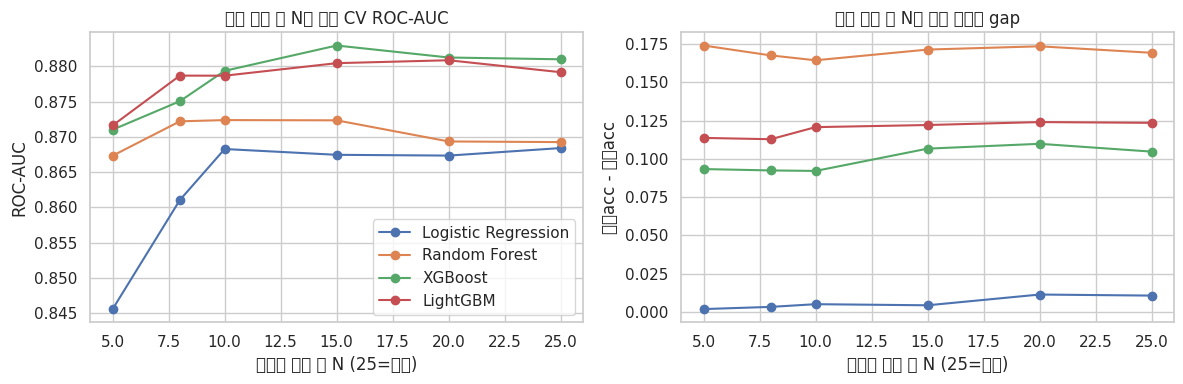

In [18]:
# 변수 개수(N)에 따른 성능/과적합 곡선 (RF 중요도 기준; N=25는 '전체')
order = ['RF top-5', 'RF top-8', 'RF top-10', 'RF top-15', 'RF top-20', '전체(선택 없음)']
xs = [5, 8, 10, 15, 20, 25]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for mn in MODELS:
    s = fs_df[fs_df['모델'] == mn].set_index('변수 선택').loc[order]
    axes[0].plot(xs, s['auc'], marker='o', label=MODEL_KR[mn]); axes[1].plot(xs, s['gap'], marker='o', label=MODEL_KR[mn])
axes[0].set_title('선택 변수 수 N에 따른 CV ROC-AUC'); axes[0].set_xlabel('선택한 변수 수 N (25=전체)'); axes[0].set_ylabel('ROC-AUC')
axes[1].set_title('선택 변수 수 N에 따른 과적합 gap'); axes[1].set_xlabel('선택한 변수 수 N (25=전체)'); axes[1].set_ylabel('학습acc - 검증acc')
axes[0].legend()
savefig('fs_curve')

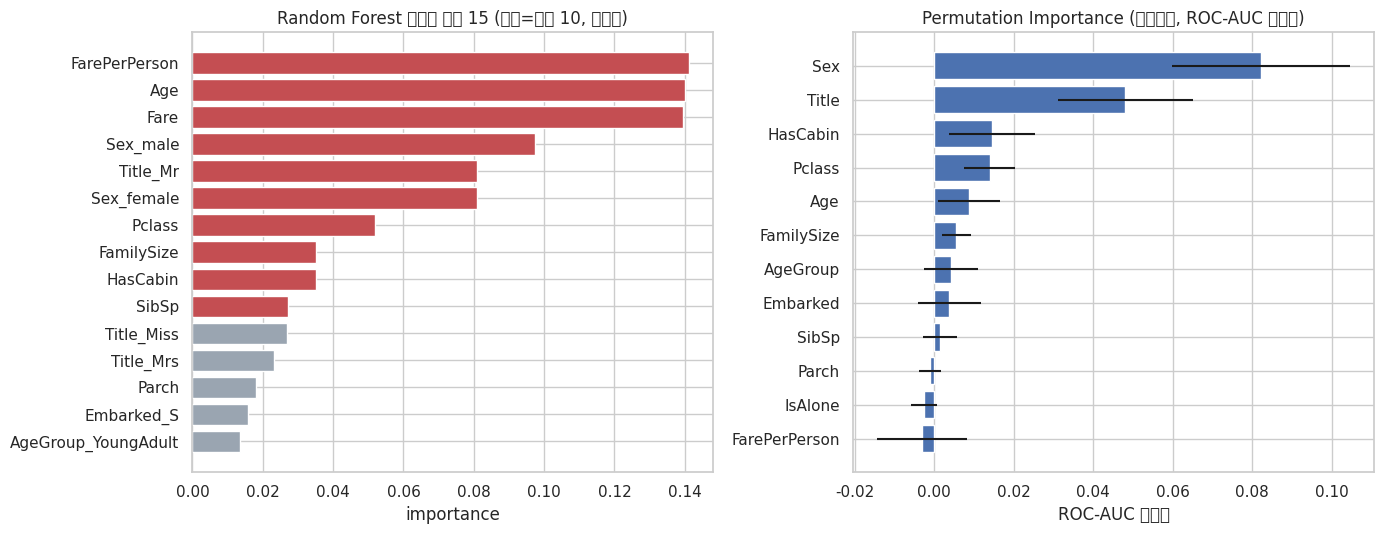

RF top-10 선택된 변수: ['Pclass', 'Age', 'SibSp', 'Fare', 'FamilySize', 'FarePerPerson', 'HasCabin', 'Sex_female', 'Sex_male', 'Title_Mr']


,0
FarePerPerson,0.1411
Age,0.1401
Fare,0.1396
Sex_male,0.0975
Title_Mr,0.0810
Sex_female,0.0808
Pclass,0.0520
FamilySize,0.0352
HasCabin,0.0351
SibSp,0.0271


In [19]:
# Feature Importance 시각화: (1) RF 불순도 중요도 (2) 홀드아웃 Permutation Importance
rf_pipe = build_pipeline(get_model('RF'), **BASE_CFG).fit(X_train, y_train)
names = [n.split('__', 1)[-1] for n in rf_pipe[:-1].get_feature_names_out()]
imp = pd.Series(rf_pipe.named_steps['model'].feature_importances_, index=names).sort_values(ascending=False)
imp.to_csv('results/rf_importance.csv', header=['importance'], encoding='utf-8-sig')

perm = permutation_importance(rf_pipe, X_hold, y_hold, scoring='roc_auc', n_repeats=30, random_state=SEED)
perm_s = pd.Series(perm.importances_mean, index=X_hold.columns); perm_sd = pd.Series(perm.importances_std, index=X_hold.columns)
perm_s = perm_s[perm_s.abs() > 0].sort_values(ascending=False)
perm_s.to_csv('results/permutation_importance.csv', header=['importance'], encoding='utf-8-sig')

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
top = imp.head(15)[::-1]
axes[0].barh(top.index, top.values, color=['#C44E52' if i in imp.head(10).index else '#9AA5B1' for i in top.index])
axes[0].set_title('Random Forest 중요도 상위 15 (빨강=상위 10, 선택됨)'); axes[0].set_xlabel('importance')
p = perm_s.head(12)[::-1]
axes[1].barh(p.index, p.values, xerr=perm_sd[p.index].values, color='#4C72B0')
axes[1].set_title('Permutation Importance (홀드아웃, ROC-AUC 감소량)'); axes[1].set_xlabel('ROC-AUC 감소량')
savefig('feature_importance')

sel_pipe = build_pipeline(get_model('RF'), **{**BASE_CFG, 'fs': ('rf', 10)}).fit(X_train, y_train)
selected10 = [n.split('__', 1)[-1] for n in sel_pipe[:-1].get_feature_names_out()]
print('RF top-10 선택된 변수:', selected10)
json.dump(selected10, open('results/selected10.json', 'w'))
imp.head(15).round(4)

## 최종 파이프라인 선정 및 하이퍼파라미터 튜닝 (GridSearchCV) — 가산점
단일 요인 실험·변수 선택 실험에서 **모델 평균 CV ROC-AUC가 가장 높았던 옵션**을 자동으로 골라 최종 파이프라인을 구성하고, 모델별로 `GridSearchCV`(5-fold, scoring=ROC-AUC)로 튜닝한다. 튜닝은 **학습 80%에서만** 수행한다.

In [20]:
final_cfg = dict(groups=ALL_FE)
for factor, (key, opts) in SINGLE.items():
    s = single[(single['요인'] == factor) & (single['옵션'] != 'Drop NA(학습 fold)')]       # Drop NA는 표본 수가 달라 최종 후보에서 제외
    best = s.groupby('옵션')['auc'].mean().idxmax()
    final_cfg[key] = opts[best]
best_fs = fs_df.groupby('변수 선택')['auc'].mean().idxmax()
final_cfg['fs'] = FS_OPTIONS[best_fs]
print('최종 파이프라인 구성:', final_cfg, '| 변수 선택:', best_fs)

PARAM_GRIDS = {
 'LR':   {'model__C': [0.01, 0.1, 1, 10]},
 'RF':   {'model__n_estimators': [200, 500], 'model__max_depth': [None, 5, 8], 'model__min_samples_leaf': [1, 3, 5]},
 'XGB':  {'model__n_estimators': [100, 300], 'model__max_depth': [2, 3, 4], 'model__learning_rate': [0.03, 0.1]},
 'LGBM': {'model__n_estimators': [100, 300], 'model__num_leaves': [7, 15], 'model__learning_rate': [0.03, 0.1]},
}
tuned, rows = {}, []
for mn in MODELS:
    pipe = build_pipeline(get_model(mn), **final_cfg)
    gs = GridSearchCV(pipe, PARAM_GRIDS[mn], scoring='roc_auc', cv=StratifiedKFold(5, shuffle=True, random_state=SEED), n_jobs=N_JOBS)
    gs.fit(X_train, y_train)
    tuned[mn] = gs.best_estimator_
    before = run_holdout(mn, final_cfg)
    pv = gs.best_estimator_.predict_proba(X_hold)[:, 1]; pr = (pv >= 0.5).astype(int)
    rows.append({'모델': mn, 'best_params': {k.replace('model__', ''): v for k, v in gs.best_params_.items()}, 'tune_cv_auc': gs.best_score_,
                 'hold_auc_before': before['hold_auc'], 'hold_acc_before': before['hold_acc'],
                 'hold_auc_after': roc_auc_score(y_hold, pv), 'hold_acc_after': accuracy_score(y_hold, pr),
                 'hold_prec_after': precision_score(y_hold, pr), 'hold_rec_after': recall_score(y_hold, pr), 'hold_f1_after': f1_score(y_hold, pr)})
    print(f'{mn} 완료 ({time.time()-t0:.0f}s)')
gs_df = pd.DataFrame(rows); gs_df.to_csv('results/gridsearch.csv', index=False, encoding='utf-8-sig')
json.dump({k: (list(v) if isinstance(v, tuple) else v) for k, v in final_cfg.items()}, open('results/final_cfg.json', 'w'))
gs_df

최종 파이프라인 구성: {'groups': ['orig', 'family', 'title', 'cabin', 'farepp', 'agegrp'], 'imputer': 'mean', 'encoder': 'onehot', 'scaler': 'minmax', 'fs': ('rf', 15)} | 변수 선택: RF top-15
LR 완료 (389s)
RF 완료 (507s)
XGB 완료 (544s)
LGBM 완료 (566s)


,모델,best_params,tune_cv_auc,hold_auc_before,hold_acc_before,hold_auc_after,hold_acc_after,hold_prec_after,hold_rec_after,hold_f1_after
0,LR,{'C': 1},0.868289,0.857576,0.798883,0.857576,0.798883,0.761905,0.695652,0.727273
1,RF,"{'max_depth': 8, 'min_samples_leaf': 1, 'n_est...",0.884833,0.842424,0.787709,0.850856,0.798883,0.761905,0.695652,0.727273
2,XGB,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti...",0.895440,0.825889,0.776536,0.824440,0.776536,0.745763,0.637681,0.687500
3,LGBM,"{'learning_rate': 0.03, 'n_estimators': 300, '...",0.894053,0.841568,0.821229,0.837220,0.787709,0.754098,0.666667,0.707692


## STEP 05. 최종 모델 평가 (홀드아웃 20%)

,모델,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.7989,0.7619,0.6957,0.7273,0.8576
1,Random Forest,0.7989,0.7619,0.6957,0.7273,0.8509
2,XGBoost,0.7765,0.7458,0.6377,0.6875,0.8244
3,LightGBM,0.7877,0.7541,0.6667,0.7077,0.8372


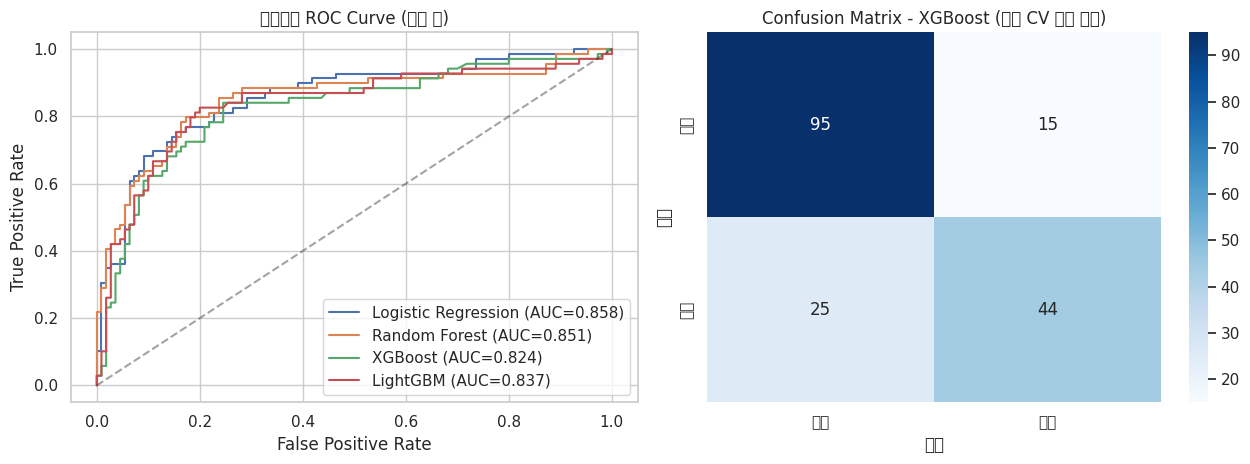

튜닝 CV 점수 기준 최고 모델: XGB
              precision    recall  f1-score   support

          사망      0.792     0.864     0.826       110
          생존      0.746     0.638     0.688        69

    accuracy                          0.777       179
   macro avg      0.769     0.751     0.757       179
weighted avg      0.774     0.777     0.773       179



In [21]:
# 튜닝된 4개 모델의 홀드아웃 성능 (Accuracy / Precision / Recall / F1 / ROC-AUC)
final_tbl = gs_df[['모델', 'hold_acc_after', 'hold_prec_after', 'hold_rec_after', 'hold_f1_after', 'hold_auc_after']].copy()
final_tbl.columns = ['모델', 'Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC']
final_tbl['모델'] = final_tbl['모델'].map(MODEL_KR)
final_tbl.round(4).to_csv('results/final_holdout.csv', index=False, encoding='utf-8-sig')
display(final_tbl.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for mn in MODELS:
    pv = tuned[mn].predict_proba(X_hold)[:, 1]; fpr, tpr, _ = roc_curve(y_hold, pv)
    axes[0].plot(fpr, tpr, label=f'{MODEL_KR[mn]} (AUC={roc_auc_score(y_hold, pv):.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', alpha=.4); axes[0].set_xlabel('False Positive Rate'); axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('홀드아웃 ROC Curve (튜닝 후)'); axes[0].legend(loc='lower right')

best_name = gs_df.sort_values('tune_cv_auc', ascending=False).iloc[0]['모델']     # 모델 선택 기준은 '튜닝 CV 점수'(홀드아웃 아님)
pred = tuned[best_name].predict(X_hold)
sns.heatmap(confusion_matrix(y_hold, pred), annot=True, fmt='d', cmap='Blues', ax=axes[1], xticklabels=['사망', '생존'], yticklabels=['사망', '생존'])
axes[1].set_xlabel('예측'); axes[1].set_ylabel('실제'); axes[1].set_title(f'Confusion Matrix - {MODEL_KR[best_name]} (튜닝 CV 최고 모델)')
savefig('roc_confusion')
print('튜닝 CV 점수 기준 최고 모델:', best_name)
print(classification_report(y_hold, pred, target_names=['사망', '생존'], digits=3))

## SHAP 기반 설명 가능성 분석 — 가산점
튜닝된 XGBoost 파이프라인의 홀드아웃 예측을 SHAP(TreeExplainer)으로 해석한다.

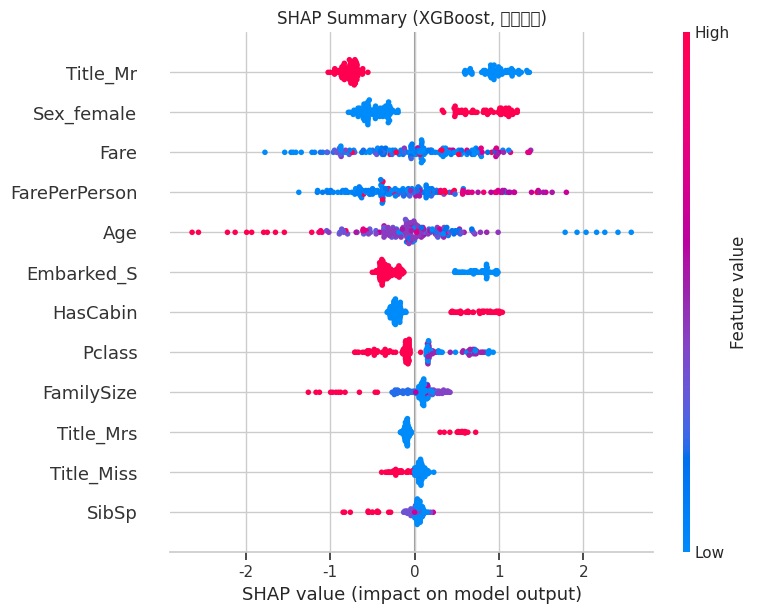

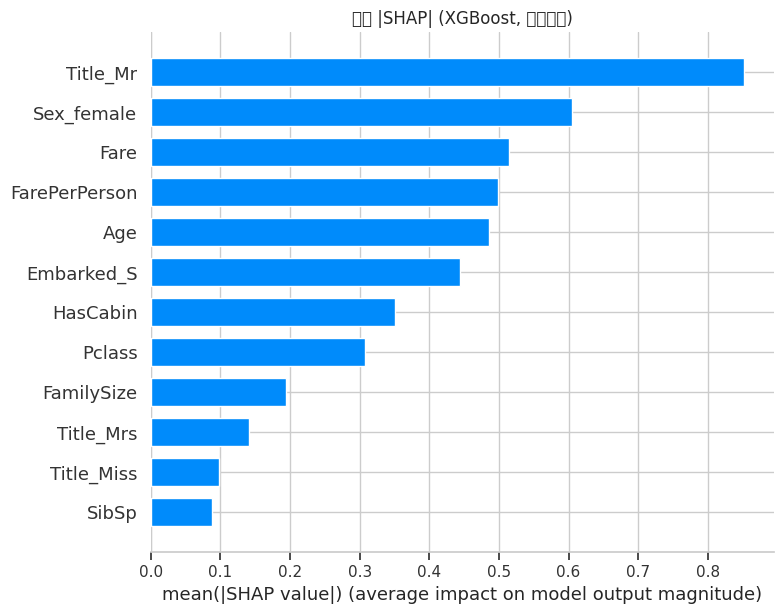

,0
Title_Mr,0.8523
Sex_female,0.6042
Fare,0.5144
FarePerPerson,0.4991
Age,0.4850
Embarked_S,0.4445
HasCabin,0.3513
Pclass,0.3081
FamilySize,0.1939
Title_Mrs,0.1408


In [22]:
import shap
xgb_pipe = tuned['XGB']
Xt = xgb_pipe[:-1].transform(X_hold)
fnames = [n.split('__', 1)[-1] for n in xgb_pipe[:-1].get_feature_names_out()]
explainer = shap.TreeExplainer(xgb_pipe.named_steps['model'])
sv = explainer.shap_values(Xt)

plt.figure(); shap.summary_plot(sv, Xt, feature_names=fnames, show=False, max_display=12)
plt.title('SHAP Summary (XGBoost, 홀드아웃)'); savefig('shap_summary')
plt.figure(); shap.summary_plot(sv, Xt, feature_names=fnames, plot_type='bar', show=False, max_display=12)
plt.title('평균 |SHAP| (XGBoost, 홀드아웃)'); savefig('shap_bar')
shap_imp = pd.Series(np.abs(sv).mean(axis=0), index=fnames).sort_values(ascending=False)
shap_imp.to_csv('results/shap_importance.csv', header=['mean_abs_shap'], encoding='utf-8-sig')
shap_imp.head(10).round(4)

## AutoML 비교 실험에 대하여
AutoML(예: FLAML, AutoGluon, TPOT) 비교는 선택 가산점 항목이며 이 노트북에서는 수행하지 않았다.

In [23]:
print(f'전체 실행 시간: {time.time()-t0:.0f}s')

전체 실행 시간: 571s


## 최종 결론 (상세 해석과 표는 제출용 PDF 보고서 참고)
1. **가장 효과적인 전처리:** 범주형 정보를 쓸 수 있게 하는 인코딩 + **Title** 파생 변수가 핵심이었다. 결측치 대체 방식(평균 AUC 차이 ≤ 0.002)과 스케일링은 영향이 거의 없었다. 4개 모델 평균 CV AUC: Base 0.756 → Exp-1 0.875 (Base는 Sex 등 범주형을 쓰지 못하므로 향상의 대부분은 범주형 정보 유무에서 비롯됨).
2. **One-Hot이 항상 좋은가?** 아니다. LR은 One-Hot이 유리(AUC 0.8684 vs Label 0.8538), 트리 모델(RF/XGB/LGBM)은 Label과 동등했다.
3. **Feature Selection과 과적합:** RF top-10은 변수를 25→10개로 줄이고도 평균 AUC를 유지(0.8747 vs 0.8745)했지만, 학습-검증 gap은 0.102 → 0.096로 거의 줄지 않았다. 과적합 감소 효과는 제한적.
4. **스케일링:** 트리 모델은 영향 없음(AUC 차이 ≤ 0.0008), LR만 미세한 차이(0.0037).
5. **Feature Engineering 기여:** 평균 AUC 0.8672 → 0.8745, Accuracy 0.8109 → 0.8239. 기여의 대부분은 Title(모델별 AUC +0.005 ~ +0.014); AgeGroup 등은 도움이 되지 않았다.

**주의:** 홀드아웃은 179명이라 정확도 표준오차가 약 3%p이다. 작은 차이는 우연일 수 있어 반복 CV 결과를 우선해 해석했다. GridSearchCV 튜닝은 홀드아웃 성능을 일관되게 개선하지못했다.